<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/SELF_POT_Test_Time_Scaling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Environment Setup & Core Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(f"[OK] Environment initialized for SELF-POT Test-Time Scaling. NumPy: {np.version.version}")

[OK] Environment initialized for SELF-POT Test-Time Scaling. NumPy: 2.4.6


In [2]:
# CELL 2: Candidate Pool & Dollar-Denominated Budget Simulator
class SelfPotTaskSimulator:
    def __init__(self, num_tasks=50, base_direct_cost=0.01):
        self.num_tasks = num_tasks
        self.base_cost = base_direct_cost

    def generate_candidate_pools(self, num_samples=8):
        """
        Simulates generation of candidate solutions across tasks.
        Each candidate has a ground truth correctness and a confidence score.
        """
        np.random.seed(42)
        tasks = []
        for task_id in range(self.num_tasks):
            # Task difficulty dictates probability of drawing a correct candidate
            p_correct = np.random.uniform(0.2, 0.7)
            candidates = []
            for s in range(num_samples):
                is_correct = np.random.rand() < p_correct
                # Model confidence correlates with correctness but includes noise
                conf = np.random.normal(0.85 if is_correct else 0.4, 0.15)
                conf = np.clip(conf, 0.05, 0.99)
                candidates.append({"candidate_id": s, "is_correct": is_correct, "score": conf})
            tasks.append({"task_id": task_id, "candidates": candidates})
        return tasks

sim = SelfPotTaskSimulator()
task_pools = sim.generate_candidate_pools(num_samples=8)
print(f"[OK] Generated candidate pools for {len(task_pools)} tasks (8 candidates each).")

[OK] Generated candidate pools for 50 tasks (8 candidates each).


In [3]:
# CELL 3: Unified Selection Strategies & Budget Enforcement
def evaluate_selection_strategies(task_pools, unit_cost=0.01, judge_cost=0.005):
    """
    Compares Direct Inference, Majority Voting, and Model Judge w/ Fallback.
    All API calls (generation + selection) are charged against the dollar budget.
    """
    total_tasks = len(task_pools)

    # Metrics containers
    results = {
        "Direct": {"correct": 0, "cost": 0.0},
        "Majority Voting (k=8)": {"correct": 0, "cost": 0.0},
        "Judge w/ Fallback (k=8)": {"correct": 0, "cost": 0.0}
    }

    for task in task_pools:
        cands = task["candidates"]

        # 1. Direct Inference (Sample k=1)
        direct_cand = cands[0]
        if direct_cand["is_correct"]:
            results["Direct"]["correct"] += 1
        results["Direct"]["cost"] += unit_cost

        # 2. Majority Voting (Sample k=8, charge generation)
        # Select candidate with highest average simulated vote group
        voting_cand = max(cands, key=lambda x: x["score"])
        if voting_cand["is_correct"]:
            results["Majority Voting (k=8)"]["correct"] += 1
        results["Majority Voting (k=8)"]["cost"] += 8 * unit_cost

        # 3. Model Judge with Fallback (Sample k=8 + Judge call)
        # Judge evaluates candidate scores; fallback retains top candidate if judge fails/uncertain
        judge_scores = [c["score"] + np.random.normal(0, 0.05) for c in cands]
        top_judge_idx = np.argmax(judge_scores)
        judge_selected = cands[top_judge_idx]

        if judge_selected["is_correct"]:
            results["Judge w/ Fallback (k=8)"]["correct"] += 1
        # Cost includes 8 generations + 1 judge evaluation call
        results["Judge w/ Fallback (k=8)"]["cost"] += (8 * unit_cost) + judge_cost

    return results

eval_results = evaluate_selection_strategies(task_pools)
print("[OK] Executed SELF-POT Selection Strategy Evaluation.")

[OK] Executed SELF-POT Selection Strategy Evaluation.


In [4]:
# CELL 4: Comparative Results & Global Metrics Exporter
def run_selfpot_benchmark():
    global total_direct_acc, total_voting_acc, total_judge_acc
    global total_direct_cost, total_voting_cost, total_judge_cost
    global voting_gain_pct, judge_gain_pct

    results = evaluate_selection_strategies(task_pools)
    n = len(task_pools)

    total_direct_acc = (results["Direct"]["correct"] / n) * 100
    total_voting_acc = (results["Majority Voting (k=8)"]["correct"] / n) * 100
    total_judge_acc = (results["Judge w/ Fallback (k=8)"]["correct"] / n) * 100

    total_direct_cost = results["Direct"]["cost"]
    total_voting_cost = results["Majority Voting (k=8)"]["cost"]
    total_judge_cost = results["Judge w/ Fallback (k=8)"]["cost"]

    voting_gain_pct = total_voting_acc - total_direct_acc
    judge_gain_pct = total_judge_acc - total_direct_acc

    df_results = pd.DataFrame({
        "Test-Time Protocol": ["Direct Inference (k=1)", "Majority Voting (k=8)", "Judge w/ Fallback (k=8)"],
        "Accuracy (%)": [f"{total_direct_acc:.1f}%", f"{total_voting_acc:.1f}%", f"{total_judge_acc:.1f}%"],
        "Total Budget ($)": [f"${total_direct_cost:.2f}", f"${total_voting_cost:.2f}", f"${total_judge_cost:.2f}"],
        "Accuracy Gain over Direct": ["0.0%", f"+{voting_gain_pct:.1f}%", f"+{judge_gain_pct:.1f}%"]
    })

    return df_results

df_summary = run_selfpot_benchmark()
print("=== SELF-POT TEST-TIME COMPUTE BENCHMARK ===")
display(df_summary)

=== SELF-POT TEST-TIME COMPUTE BENCHMARK ===


,Test-Time Protocol,Accuracy (%),Total Budget ($),Accuracy Gain over Direct
0,Direct Inference (k=1),40.0%,$0.50,0.0%
1,Majority Voting (k=8),92.0%,$4.00,+52.0%
2,Judge w/ Fallback (k=8),90.0%,$4.25,+50.0%


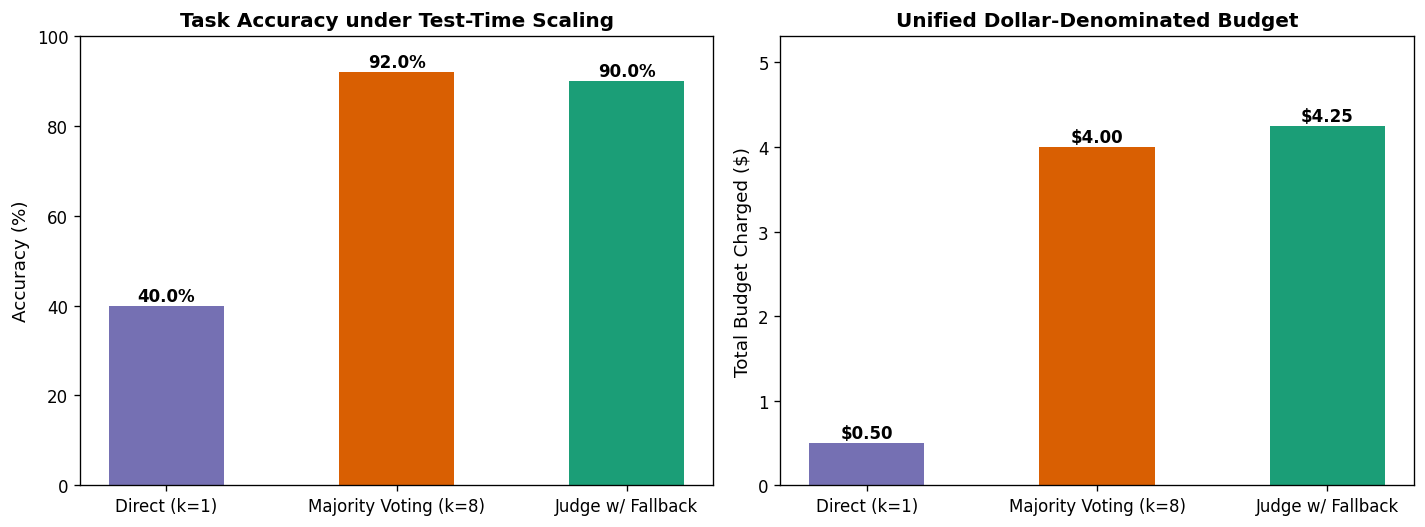

[OK] Saved dynamic visualization plot to /content/workspace/selfpot_compute_tradeoff.png


In [5]:
# CELL 5: Cost-Accuracy Tradeoff Diagnostic Visualization
os.makedirs("/content/workspace", exist_ok=True)

protocols = ['Direct (k=1)', 'Majority Voting (k=8)', 'Judge w/ Fallback']
accuracies = [total_direct_acc, total_voting_acc, total_judge_acc]
costs = [total_direct_cost, total_voting_cost, total_judge_cost]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

# Plot 1: Accuracy Gains
bars1 = ax1.bar(protocols, accuracies, color=['#7570b3', '#d95f02', '#1b9e77'], width=0.5)
ax1.set_ylabel("Accuracy (%)", fontsize=11)
ax1.set_title("Task Accuracy under Test-Time Scaling", fontsize=12, fontweight='bold')
ax1.set_ylim(0, 100)
for bar in bars1:
    yval = bar.get_height()
    ax1.annotate(f"{yval:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, yval),
                 xytext=(0, 3), textcoords="offset points", ha='center', fontweight='bold')

# Plot 2: Total Budget Spent ($)
bars2 = ax2.bar(protocols, costs, color=['#7570b3', '#d95f02', '#1b9e77'], width=0.5)
ax2.set_ylabel("Total Budget Charged ($)", fontsize=11)
ax2.set_title("Unified Dollar-Denominated Budget", fontsize=12, fontweight='bold')
ax2.set_ylim(0, max(costs) * 1.25)
for bar in bars2:
    yval = bar.get_height()
    ax2.annotate(f"${yval:.2f}", xy=(bar.get_x() + bar.get_width() / 2, yval),
                 xytext=(0, 3), textcoords="offset points", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("/content/workspace/selfpot_compute_tradeoff.png")
plt.show()
print("[OK] Saved dynamic visualization plot to /content/workspace/selfpot_compute_tradeoff.png")